KANTOROVICH TRANSPORT PROBLEM
Number of bakeries = 3
Number of cafes = 4
Total supply = 15.0
Total demand = 15.0

PASS: Supply and demand are balanced.

EUCLIDEAN COST MATRIX
[[2.2361 5.3852 5.3852 7.8102]
 [5.3852 2.2361 6.4031 5.    ]
 [4.4721 4.4721 1.4142 3.1623]]

SQUARED EUCLIDEAN COST MATRIX
[[ 5. 29. 29. 61.]
 [29.  5. 41. 25.]
 [20. 20.  2. 10.]]

EUCLIDEAN COST OPTIMAL TRANSPORT
Optimization success = True
Solver message = Optimization terminated successfully. (HiGHS Status 7: Optimal)

Optimal transport matrix gamma:
[[3. 0. 2. 0.]
 [0. 4. 0. 2.]
 [0. 0. 3. 1.]]

Optimal transportation cost = 43.8277238040552

Row sums / amount shipped by each bakery:
[5. 6. 4.]
Required supplies:
[5. 6. 4.]
PASS: All supply constraints satisfied.

Column sums / amount received by each cafe:
[3. 4. 5. 3.]
Required demands:
[3. 4. 5. 3.]
PASS: All demand constraints satisfied.
PASS: All gamma_ij are nonnegative.

Cost from solver = 43.8277238040552
Cost recomputed manually = 43.82772380405519

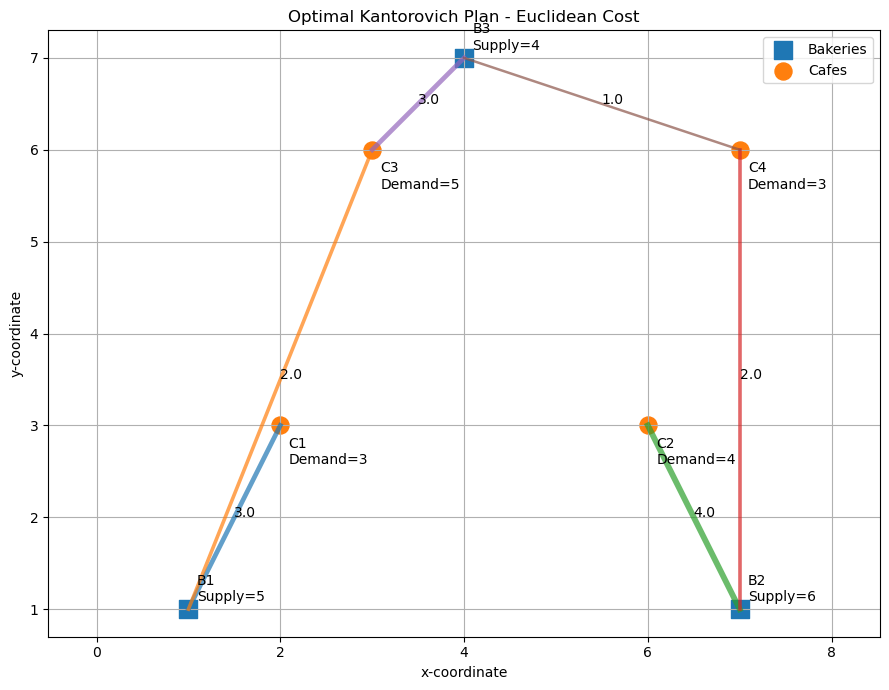

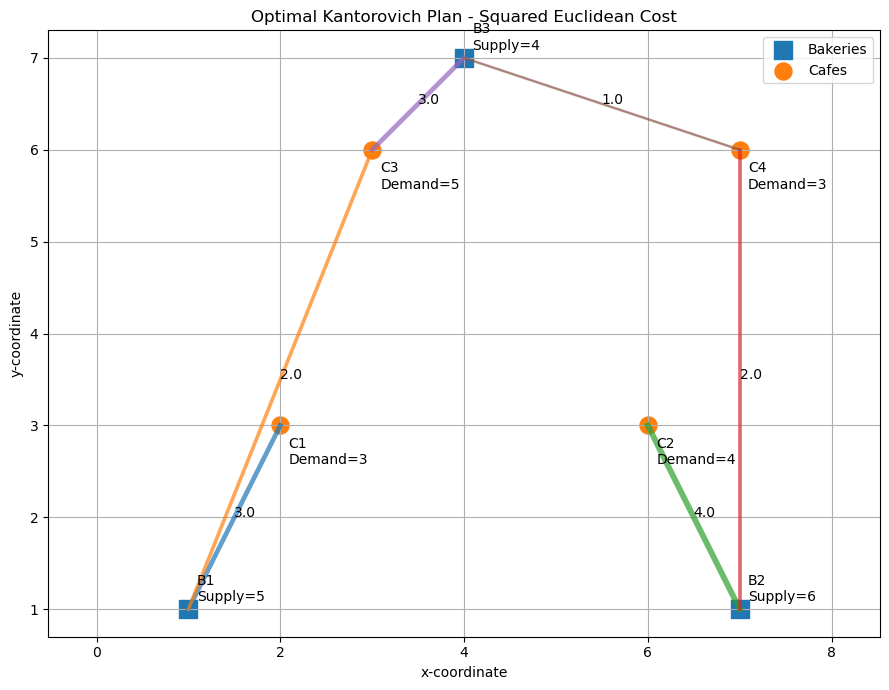


FINAL VERIFICATION
PASS: Kantorovich linear program solved.
PASS: Bakery supply constraints verified.
PASS: Cafe demand constraints verified.
PASS: Nonnegativity verified.
PASS: Objective cost independently recomputed.


In [1]:
# ============================================================
# HOMEWORK 3.1 - PART II
# KANTOROVICH OPTIMAL TRANSPORT
# STANDALONE VERIFICATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import linprog


# ============================================================
# DATA FROM PART I
# ============================================================

bakery_locations = np.array([
    [1.0, 1.0],
    [7.0, 1.0],
    [4.0, 7.0]
])


bakery_supply = np.array([
    5.0,
    6.0,
    4.0
])


cafe_locations = np.array([
    [2.0, 3.0],
    [6.0, 3.0],
    [3.0, 6.0],
    [7.0, 6.0]
])


cafe_demand = np.array([
    3.0,
    4.0,
    5.0,
    3.0
])


N = len(
    bakery_supply
)

M = len(
    cafe_demand
)


# ============================================================
# VERIFY BALANCED PROBLEM
# ============================================================

total_supply = np.sum(
    bakery_supply
)

total_demand = np.sum(
    cafe_demand
)


assert np.isclose(
    total_supply,
    total_demand
)


assert np.all(
    bakery_supply > 0
)


assert np.all(
    cafe_demand > 0
)


print("=" * 70)

print(
    "KANTOROVICH TRANSPORT PROBLEM"
)

print("=" * 70)

print(
    "Number of bakeries =",
    N
)

print(
    "Number of cafes =",
    M
)

print(
    "Total supply =",
    total_supply
)

print(
    "Total demand =",
    total_demand
)

print()

print(
    "PASS: Supply and demand are balanced."
)


# ============================================================
# COST MATRICES
# ============================================================

difference = (

    bakery_locations[:, None, :]

    -

    cafe_locations[None, :, :]
)


euclidean_cost = np.sqrt(

    np.sum(
        difference**2,
        axis=2
    )
)


squared_cost = np.sum(
    difference**2,
    axis=2
)


print()

print("=" * 70)

print(
    "EUCLIDEAN COST MATRIX"
)

print("=" * 70)

print(
    np.round(
        euclidean_cost,
        4
    )
)


print()

print("=" * 70)

print(
    "SQUARED EUCLIDEAN COST MATRIX"
)

print("=" * 70)

print(
    squared_cost
)


# ============================================================
# BUILD LINEAR PROGRAM CONSTRAINTS
#
# There are N*M variables:
#
# gamma_11, gamma_12, ..., gamma_NM
# ============================================================

number_of_variables = (
    N * M
)


A_eq = []

b_eq = []


# ============================================================
# SUPPLY CONSTRAINTS
#
# Sum_j gamma_ij = a_i
# ============================================================

for i in range(N):

    row = np.zeros(
        number_of_variables
    )


    for j in range(M):

        index = (
            i * M + j
        )

        row[index] = 1.0


    A_eq.append(
        row
    )

    b_eq.append(
        bakery_supply[i]
    )


# ============================================================
# DEMAND CONSTRAINTS
#
# Sum_i gamma_ij = b_j
# ============================================================

for j in range(M):

    row = np.zeros(
        number_of_variables
    )


    for i in range(N):

        index = (
            i * M + j
        )

        row[index] = 1.0


    A_eq.append(
        row
    )

    b_eq.append(
        cafe_demand[j]
    )


A_eq = np.array(
    A_eq
)


b_eq = np.array(
    b_eq
)


# Every gamma_ij must be nonnegative

bounds = [

    (0, None)

    for _ in range(
        number_of_variables
    )

]


# ============================================================
# FUNCTION TO SOLVE A KANTOROVICH PROBLEM
# ============================================================

def solve_kantorovich(
    cost_matrix,
    name
):

    objective = cost_matrix.flatten()


    result = linprog(

        c=objective,

        A_eq=A_eq,

        b_eq=b_eq,

        bounds=bounds,

        method="highs"
    )


    print()

    print("=" * 70)

    print(
        name
    )

    print("=" * 70)


    print(
        "Optimization success =",
        result.success
    )

    print(
        "Solver message =",
        result.message
    )


    if not result.success:

        raise RuntimeError(
            "Linear program failed."
        )


    gamma = result.x.reshape(
        N,
        M
    )


    total_cost = result.fun


    print()

    print(
        "Optimal transport matrix gamma:"
    )

    print(
        np.round(
            gamma,
            6
        )
    )


    print()

    print(
        "Optimal transportation cost =",
        total_cost
    )


    # ========================================================
    # VERIFY SUPPLY CONSTRAINTS
    # ========================================================

    shipped_from_bakeries = np.sum(
        gamma,
        axis=1
    )


    print()

    print(
        "Row sums / amount shipped by each bakery:"
    )

    print(
        shipped_from_bakeries
    )

    print(
        "Required supplies:"
    )

    print(
        bakery_supply
    )


    assert np.allclose(
        shipped_from_bakeries,
        bakery_supply
    )


    print(
        "PASS: All supply constraints satisfied."
    )


    # ========================================================
    # VERIFY DEMAND CONSTRAINTS
    # ========================================================

    received_by_cafes = np.sum(
        gamma,
        axis=0
    )


    print()

    print(
        "Column sums / amount received by each cafe:"
    )

    print(
        received_by_cafes
    )

    print(
        "Required demands:"
    )

    print(
        cafe_demand
    )


    assert np.allclose(
        received_by_cafes,
        cafe_demand
    )


    print(
        "PASS: All demand constraints satisfied."
    )


    # ========================================================
    # VERIFY NONNEGATIVITY
    # ========================================================

    assert np.all(
        gamma >= -1e-10
    )


    print(
        "PASS: All gamma_ij are nonnegative."
    )


    # ========================================================
    # MANUAL COST VERIFICATION
    # ========================================================

    manual_cost = np.sum(
        gamma
        *
        cost_matrix
    )


    print()

    print(
        "Cost from solver =",
        total_cost
    )

    print(
        "Cost recomputed manually =",
        manual_cost
    )


    assert np.isclose(
        total_cost,
        manual_cost
    )


    print(
        "PASS: Objective value verified manually."
    )


    return (
        gamma,
        total_cost
    )


# ============================================================
# SOLVE WITH EUCLIDEAN COST
# ============================================================

gamma_euclidean, cost_euclidean = (
    solve_kantorovich(

        euclidean_cost,

        "EUCLIDEAN COST OPTIMAL TRANSPORT"
    )
)


# ============================================================
# SOLVE WITH SQUARED EUCLIDEAN COST
# ============================================================

gamma_squared, cost_squared = (
    solve_kantorovich(

        squared_cost,

        "SQUARED EUCLIDEAN COST OPTIMAL TRANSPORT"
    )
)


# ============================================================
# READABLE TRANSPORT TABLES
# ============================================================

bakery_names = [
    "Bakery 1",
    "Bakery 2",
    "Bakery 3"
]


cafe_names = [
    "Cafe 1",
    "Cafe 2",
    "Cafe 3",
    "Cafe 4"
]


gamma_euclidean_df = pd.DataFrame(

    gamma_euclidean,

    index=bakery_names,

    columns=cafe_names
)


gamma_squared_df = pd.DataFrame(

    gamma_squared,

    index=bakery_names,

    columns=cafe_names
)


print()

print("=" * 70)

print(
    "EUCLIDEAN OPTIMAL TRANSPORT PLAN"
)

print("=" * 70)

print()

print(
    gamma_euclidean_df
)


print()

print("=" * 70)

print(
    "SQUARED-DISTANCE OPTIMAL TRANSPORT PLAN"
)

print("=" * 70)

print()

print(
    gamma_squared_df
)


# ============================================================
# CHECK WHETHER BOTH COSTS PRODUCED SAME PLAN
# ============================================================

same_plan = np.allclose(

    gamma_euclidean,

    gamma_squared
)


print()

print(
    "Do Euclidean and squared Euclidean costs "
    "produce the same plan?"
)

print(
    same_plan
)


# ============================================================
# FUNCTION TO PLOT TRANSPORT PLAN
# ============================================================

def plot_transport_plan(
    gamma,
    title,
    filename
):

    plt.figure(
        figsize=(9, 7)
    )


    # Bakeries

    plt.scatter(

        bakery_locations[:, 0],

        bakery_locations[:, 1],

        s=150,

        marker="s",

        label="Bakeries"
    )


    # Cafes

    plt.scatter(

        cafe_locations[:, 0],

        cafe_locations[:, 1],

        s=150,

        marker="o",

        label="Cafes"
    )


    # ========================================================
    # DRAW NONZERO TRANSPORT CONNECTIONS
    # ========================================================

    for i in range(N):

        for j in range(M):

            amount = gamma[
                i,
                j
            ]


            if amount > 1e-8:

                x_values = [

                    bakery_locations[i, 0],

                    cafe_locations[j, 0]
                ]


                y_values = [

                    bakery_locations[i, 1],

                    cafe_locations[j, 1]
                ]


                plt.plot(

                    x_values,

                    y_values,

                    linewidth=(
                        1
                        +
                        0.8 * amount
                    ),

                    alpha=0.7
                )


                midpoint_x = (
                    x_values[0]
                    +
                    x_values[1]
                ) / 2


                midpoint_y = (
                    y_values[0]
                    +
                    y_values[1]
                ) / 2


                plt.annotate(

                    f"{amount:.1f}",

                    (
                        midpoint_x,
                        midpoint_y
                    )
                )


    # Bakery labels

    for i, (x, y) in enumerate(
        bakery_locations
    ):

        plt.annotate(

            f"B{i+1}\nSupply={bakery_supply[i]:.0f}",

            (x, y),

            xytext=(6, 6),

            textcoords="offset points"
        )


    # Cafe labels

    for j, (x, y) in enumerate(
        cafe_locations
    ):

        plt.annotate(

            f"C{j+1}\nDemand={cafe_demand[j]:.0f}",

            (x, y),

            xytext=(6, -28),

            textcoords="offset points"
        )


    plt.xlabel(
        "x-coordinate"
    )

    plt.ylabel(
        "y-coordinate"
    )

    plt.title(
        title
    )

    plt.grid(
        True
    )

    plt.legend()

    plt.axis(
        "equal"
    )

    plt.tight_layout()


    plt.savefig(
        filename,
        dpi=300
    )


    plt.show()


# ============================================================
# PLOT EUCLIDEAN SOLUTION
# ============================================================

plot_transport_plan(

    gamma_euclidean,

    "Optimal Kantorovich Plan - Euclidean Cost",

    "kantorovich_euclidean_plan.png"
)


# ============================================================
# PLOT SQUARED-DISTANCE SOLUTION
# ============================================================

plot_transport_plan(

    gamma_squared,

    "Optimal Kantorovich Plan - Squared Euclidean Cost",

    "kantorovich_squared_plan.png"
)


# ============================================================
# FINAL VERIFICATION
# ============================================================

print()

print("=" * 70)

print(
    "FINAL VERIFICATION"
)

print("=" * 70)


print(
    "PASS: Kantorovich linear program solved."
)

print(
    "PASS: Bakery supply constraints verified."
)

print(
    "PASS: Cafe demand constraints verified."
)

print(
    "PASS: Nonnegativity verified."
)

print(
    "PASS: Objective cost independently recomputed."
)